### Problem 12 : The Right to be Forgotten on real personal data - and who pays for it

⏱️ ~45 min · 🧭 Stage 6 (Real-world Responsible AI), rung 8 · 📄 `resources/papers/01-foundations/2019-guo-certified-data-removal.pdf`, book chapter on fairness (`resources/book/`)

> 🔗 **Building on Problem 11 :** we now have an audit protocol : a gold band, U-LiRA, utility, cost and the relearn
> attack. Every request so far was on 8×8 digits, and every request was *one* request.

Real systems are different in two ways. The data is **personal** : names, ages, incomes, marital status. And requests
arrive **continuously and not at random** : the people who exercise their rights are not a random sample of the people
in your data. This problem uses the **UCI Adult census dataset** (30,162 people; the same dataset as the book's fairness
chapter) and an income model, a stand-in for a credit-limit or hiring-screen model.

> 🟢 **In plain words :** forgetting one person is a privacy question. Forgetting *many* people, if they are mostly
> from one group, quietly becomes a **fairness** question. The model learns from whoever is left, and if the people
> who leave are mostly, say, high-earning women, the model ends up believing women rarely earn much.

> 🔴 **For practitioners :** GDPR Art. 17 requires erasure "without undue delay", Art. 12(3) sets one month to act on a
> request. India's DPDP Act s.12 and California's CCPA §1798.105 give similar rights. Degraded model quality is **not**
> one of the Art. 17(3) exceptions, so you cannot refuse a request because it hurts your model. You *can*, and under
> the EU AI Act's data-governance duties for high-risk systems arguably *must*, **monitor and mitigate** the effect.
> This problem builds that monitor into the unlearning audit.

**TASK :** Serve erasure requests on a real income model, first with a classical model (exact-ish Newton removal,
rung 2), then with a neural network (approximate methods, rungs 6-7). Measure **who pays** for the deletions, and fix it.

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.base import BaseEstimator, ClassifierMixin
from fairlearn.metrics import MetricFrame, true_positive_rate, selection_rate
from fairlearn.postprocessing import ThresholdOptimizer
from mul import data, classical, train, nn, methods, audit, viz
viz.style()

X, y, meta = data.load_adult()
rng = np.random.default_rng(0)
perm = rng.permutation(len(X)); n_train = int(0.7 * len(X))
tr, te = perm[:n_train], perm[n_train:]
X_train, y_train, m_train = X[tr], y[tr], meta.iloc[tr].reset_index(drop=True)
X_test, y_test, m_test = X[te], y[te], meta.iloc[te].reset_index(drop=True)

print(f"{len(X):,} people, {X.shape[1]} features (one-hot + standardised), {y.mean():.0%} earn > $50K")
print(pd.crosstab(m_train.sex, y_train, normalize="index").rename(columns={0: "<= 50K", 1: "> 50K"}).round(3))

30,162 people, 104 features (one-hot + standardised), 25% earn > $50K
col_0   <= 50K  > 50K
sex                  
Female   0.886  0.114
Male     0.686  0.314


Even before any deletion, the data is unbalanced : about a third of the people are women, and only ~11% of women earn
more than $50K versus ~31% of men. Only **778 women** in the training set have the positive label. Keep that number in
mind.

#### Step 1 : Train - the classical model first, and a fairness baseline

We use L2-regularised logistic regression trained to optimality with Newton's method (Problem 2), and measure fairness
with `fairlearn` (Bird et al. 2020, used in the book). The metric is **equal opportunity** : among people who *really*
earn > $50K, how often does the model say so (true-positive rate, TPR), per group? A credit or hiring model with a lower
TPR for women denies qualified women more often.

In [3]:
# Step 1: train + fairness baseline
def fairness(pred):
    """Accuracy, per-group true-positive rate and selection rate on the test set."""
    g = MetricFrame(metrics={"tpr": true_positive_rate, "sel": selection_rate}, y_true=y_test, y_pred=pred,
                    sensitive_features=m_test.sex).by_group
    return dict(accuracy=(pred == y_test).mean(), TPR_women=g.loc["Female", "tpr"], TPR_men=g.loc["Male", "tpr"],
                TPR_gap=g.loc["Male", "tpr"] - g.loc["Female", "tpr"], selected_women=g.loc["Female", "sel"],
                selected_men=g.loc["Male", "sel"])

LAM = 1.0
original = classical.LogisticNewton(lam=LAM).fit(X_train, y_train)
print(f"trained in {original.fit_seconds * 1000:.0f} ms, {original.n_iter} Newton iterations")
print(pd.Series(fairness(original.predict(X_test))).round(3).to_string())

trained in 49 ms, 9 Newton iterations
accuracy          0.857
TPR_women         0.506
TPR_men           0.635
TPR_gap           0.129
selected_women    0.076
selected_men      0.261


The model is ~86% accurate and already has a TPR gap of about 13 points between men and women. That gap comes from the
data and is the starting point. The question for this problem is what **unlearning** does to it.

#### Step 2 : Show the issue - one request is easy, a wave of requests is not

First, one person. "Alice" is a woman in the training set who earns > $50K and asks to be erased. We remove her with
the one-step Newton update from Problem 2 and compare with an exact retrain.

In [4]:
# Step 2a: one erasure request
women_hi = np.where((m_train.sex == "Female") & (y_train == 1))[0]
alice = women_hi[0]
keep = np.setdiff1d(np.arange(n_train), [alice])
unlearned = original.unlearn_newton(X_train[keep], y_train[keep], X_train[[alice]], y_train[[alice]])
retrained = classical.LogisticNewton(lam=LAM).fit(X_train[keep], y_train[keep])

def retain_grad_norm(model, Xr, yr):
    """‖∇ of the retain objective‖ at the model's weights - zero exactly at the retrained optimum (Guo et al. 2019)."""
    return np.linalg.norm(model.per_example_grad(Xr, yr).sum(0) + LAM * model.w)

p = lambda m: m.predict_proba(X_train[[alice]])[0, 1]
print(f"P(Alice > 50K):  original {p(original):.4f}   Newton-unlearned {p(unlearned):.4f}   retrained {p(retrained):.4f}")
print(f"max |w_unlearned - w_retrained| = {np.abs(unlearned.w - retrained.w).max():.1e}   "
      f"(original vs retrained: {np.abs(original.w - retrained.w).max():.1e})")
print(f"retain-gradient norm: original {retain_grad_norm(original, X_train[keep], y_train[keep]):.2e}, "
      f"unlearned {retain_grad_norm(unlearned, X_train[keep], y_train[keep]):.2e}")

P(Alice > 50K):  original 0.3180   Newton-unlearned 0.3163   retrained 0.3163
max |w_unlearned - w_retrained| = 2.2e-06   (original vs retrained: 2.9e-03)
retain-gradient norm: original 2.18e+00, unlearned 1.49e-03


One person in 21,000 barely moves a well-regularised linear model, and the Newton step lands essentially on the retrained
optimum : the gradient of the retain objective is near zero, which is the certificate from Guo et al. (2019). For
one request, this is a solved problem.

Now the realistic case. Requests do not arrive one at a time from a random sample. Suppose a professional women's
network runs a privacy campaign, and over a quarter a growing share of **high-earning women** ask to be deleted. As a
control, we delete the **same number of randomly chosen people**.

In [5]:
# Step 2b + 3: waves of requests - skewed vs random - each served by Newton removal AND exact retrain
rows = []
for frac in [0.0, 0.15, 0.30, 0.45, 0.60, 0.75, 0.90]:
    n_del = int(frac * len(women_hi))
    for kind in ["skewed (high-earning women)", "random (same number)"]:
        pool = women_hi if kind.startswith("skewed") else np.arange(n_train)
        forget = np.random.default_rng(1).choice(pool, n_del, replace=False)
        keep = np.setdiff1d(np.arange(n_train), forget)
        ret = classical.LogisticNewton(lam=LAM).fit(X_train[keep], y_train[keep])
        unl = original.unlearn_newton(X_train[keep], y_train[keep], X_train[forget], y_train[forget]) if n_del else original
        for method, m in [("retrain (exact)", ret), ("Newton step", unl)]:
            rows.append(dict(deleted=n_del, share_of_women_hi=frac, kind=kind, method=method,
                             w_error=np.abs(m.w - ret.w).max(), **fairness(m.predict(X_test))))
waves = pd.DataFrame(rows)
print(waves[waves.method == "retrain (exact)"].pivot(index="deleted", columns="kind", values=["accuracy", "TPR_women", "TPR_gap"]).round(3).to_string())

                    accuracy                                        TPR_women                                          TPR_gap                            
kind    random (same number) skewed (high-earning women) random (same number) skewed (high-earning women) random (same number) skewed (high-earning women)
deleted                                                                                                                                                   
0                      0.857                       0.857                0.506                       0.506                0.129                       0.129
116                    0.856                       0.855                0.506                       0.473                0.128                       0.160
233                    0.857                       0.857                0.509                       0.446                0.126                       0.189
350                    0.856                       0.855              

#### Step 4 : Show the result

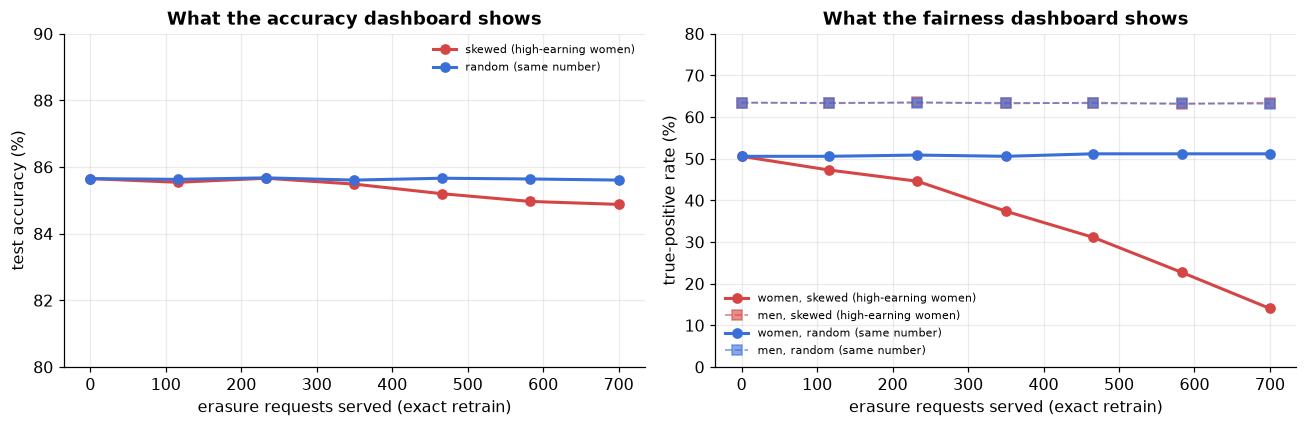

In [6]:
# Step 4: the accuracy dashboard vs the fairness dashboard
ex = waves[waves.method == "retrain (exact)"]
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharex=True)
for kind, c in [("skewed (high-earning women)", viz.FORGET), ("random (same number)", viz.RETAIN)]:
    d = ex[ex.kind == kind]
    axes[0].plot(d.deleted, 100 * d.accuracy, "o-", color=c, lw=2, label=kind)
    axes[1].plot(d.deleted, 100 * d.TPR_women, "o-", color=c, lw=2, label=f"women, {kind}")
    axes[1].plot(d.deleted, 100 * d.TPR_men, "s--", color=c, lw=1.2, alpha=0.6, label=f"men, {kind}")
axes[0].set_ylim(80, 90); axes[0].set_ylabel("test accuracy (%)"); axes[0].set_title("What the accuracy dashboard shows")
axes[1].set_ylim(0, 80); axes[1].set_ylabel("true-positive rate (%)"); axes[1].set_title("What the fairness dashboard shows")
for ax in axes:
    ax.set_xlabel("erasure requests served (exact retrain)"); ax.legend(fontsize=7.5)
plt.tight_layout(); plt.show()

**Stop and notice what just happened.** On the left, nothing happens : test accuracy moves by less than one point
whichever people are deleted. On the right, as the skewed requests are served, the model's TPR for women collapses,
while the men's line does not move. Deleting the same number of *random* people changes nothing.

And these are **exact** retrains. Nothing is wrong with the unlearning : the model faithfully became the model you
would have trained on the data that is left, and that data now says high-earning women barely exist. **Perfect
unlearning faithfully reproduces whatever bias the deletions introduce.**

> 🔴 **For practitioners :** this is a distribution shift caused by *label-correlated, group-correlated* deletions. Two
> things make it dangerous in practice. (1) Standard model monitoring tracks accuracy and input drift; neither moves.
> (2) Each request is lawful and individually tiny, so no single change review would catch it. Only a **per-group
> metric tracked across the deletion log** reveals it.

#### Step 5 : Prove it - is the Newton step still as good as a retrain at this scale?

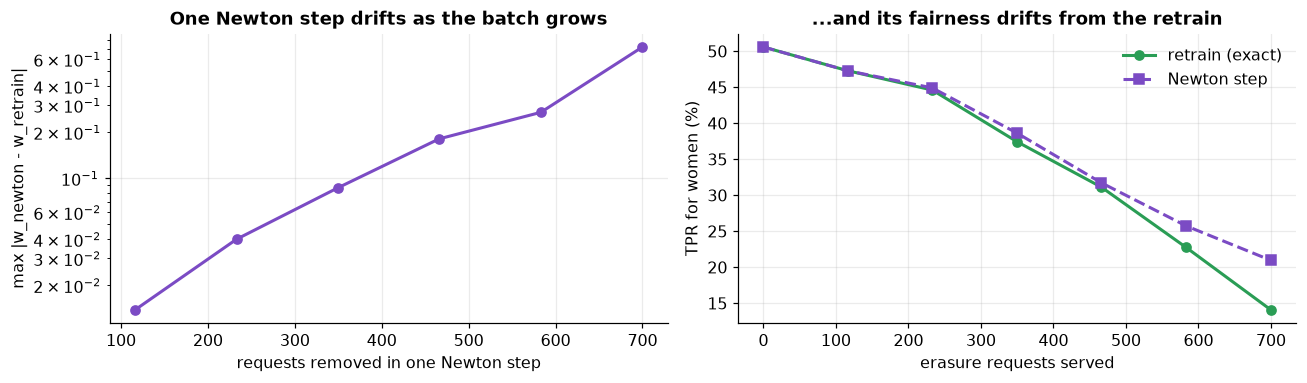

            w_error                   TPR_women                
method  Newton step retrain (exact) Newton step retrain (exact)
deleted                                                        
0            0.0000             0.0      0.5060          0.5060
116          0.0138             0.0      0.4731          0.4731
233          0.0401             0.0      0.4491          0.4461
350          0.0870             0.0      0.3862          0.3743
466          0.1811             0.0      0.3174          0.3114
583          0.2700             0.0      0.2575          0.2275
700          0.7216             0.0      0.2096          0.1407


In [7]:
# Step 5a: Newton removal error vs number of deletions (skewed waves)
sk = waves[waves.kind.str.startswith("skewed")].pivot(index="deleted", columns="method", values=["w_error", "TPR_women"])
fig, axes = plt.subplots(1, 2, figsize=(12, 3.6))
axes[0].semilogy(sk.index[1:], sk[("w_error", "Newton step")].iloc[1:], "o-", color=viz.METHOD, lw=2)
axes[0].set_xlabel("requests removed in one Newton step"); axes[0].set_ylabel("max |w_newton - w_retrain|")
axes[0].set_title("One Newton step drifts as the batch grows")
axes[1].plot(sk.index, 100 * sk[("TPR_women", "retrain (exact)")], "o-", color=viz.RETRAIN, lw=2, label="retrain (exact)")
axes[1].plot(sk.index, 100 * sk[("TPR_women", "Newton step")], "s--", color=viz.METHOD, lw=2, label="Newton step")
axes[1].set_xlabel("erasure requests served"); axes[1].set_ylabel("TPR for women (%)"); axes[1].legend()
axes[1].set_title("...and its fairness drifts from the retrain")
plt.tight_layout(); plt.show()
print(sk.round(4).to_string())

For small batches the Newton step matches the retrain on the weights and on the fairness metrics. As the batch of
removed people grows, one step is no longer enough : the quadratic approximation from Problem 2 is only good near the
old optimum. That is why Guo et al. keep an **error budget**. Each removal spends some of it, and when it runs out the
system retrains from scratch.

At this model's size, retraining takes about as long as one Newton step, so the honest engineering advice is **just
retrain**. Problem 2 showed where the Newton step starts to pay off (hundreds of thousands of rows, wide features).

#### Now the deep model : does the *method* add its own unfairness ?

With the exact methods, any fairness damage comes from the deletions themselves. Approximate methods can add their own.
Gradient ascent and NegGrad+ push the model to be *wrong* on the forget set, and here every row of the forget set is
"a woman who earns > $50K". Being wrong on those rows sounds a lot like "predict that women earn less".

We train a small MLP (104 → 64 → 64 → 2), serve the 30% skewed wave (233 women) with each method, and audit the result
as in Problem 11, adding one more check : **FAIRNESS**, the women's TPR must stay inside the band of the retrained
references, the same way forget accuracy does.

In [8]:
# Deep model: same request, approximate methods, audit + FAIRNESS check
FIT = dict(epochs=20, lr=1e-3, batch_size=128)
mlp = lambda: nn.MLP(X.shape[1], 2, (64, 64))
forget = np.random.default_rng(1).choice(women_hi, int(0.30 * len(women_hi)), replace=False)
keep = np.setdiff1d(np.arange(n_train), forget)
Xr, yr, Xf, yf = X_train[keep], y_train[keep], X_train[forget], y_train[forget]
splits = dict(Xr=Xr, yr=yr, Xf=Xf, yf=yf, Xt=X_test, yt=y_test)

net = train.fit(mlp, X_train, y_train, seed=0, **FIT)
OUT = [train.fit(mlp, Xr, yr, seed=s, **FIT) for s in range(100, 112)]
IN = [train.fit(mlp, X_train, y_train, seed=s, **FIT) for s in range(1, 9)]
band_mean, band_std = audit.gold_band(OUT, splits, in_models=IN, mia=False)

# settings fixed in advance (Problem 11), scaled to a 20x larger dataset
runs = {"original": net,
        "retrain": train.fit(mlp, Xr, yr, seed=999, **FIT),
        "fine-tune": methods.finetune(net, Xr, yr, epochs=2, lr=1e-3)[0],
        "gradient ascent": methods.gradient_ascent(net, Xf, yf, epochs=5, lr=1e-4)[0],
        "NegGrad+": methods.neggrad_plus(net, Xr, yr, Xf, yf, epochs=2, alpha=0.9, lr=1e-4)[0],
        "SCRUB": methods.scrub(net, Xr, yr, Xf, steps=4, max_steps=2, lr=5e-4, forget_batch_size=8, T=1.0)[0],
        "Bad Teacher": methods.bad_teacher(net, mlp, Xr, Xf, retain_fraction=0.1)[0]}

table = audit.audit(runs, splits, OUT, in_models=IN, mia=False)
table = table.join(audit.gate(table, band_mean, band_std))
fair = pd.DataFrame({k: fairness(train.predict(m, X_test)) for k, m in runs.items()}).T
ref_tpr = np.array([fairness(train.predict(m, X_test))["TPR_women"] for m in OUT])
half = max(2 * ref_tpr.std(), 0.03)
table["TPR_women"], table["TPR_gap"] = fair.TPR_women, fair.TPR_gap
table["FAIRNESS"] = np.where((table.TPR_women - ref_tpr.mean()).abs() <= half, "ok", "x")
table["verdict"] = np.where((table.verdict == "PASS") & (table.FAIRNESS == "ok"), "PASS", "FAIL")
print(f"retrained references: TPR for women {ref_tpr.mean():.3f} ± {half:.3f}")
print(table[["forget_acc", "test_acc", "ulira", "TPR_women", "TPR_gap", "FORGET", "PRIVACY", "UTILITY", "FAIRNESS", "verdict"]].round(3).to_string())

retrained references: TPR for women 0.518 ± 0.125
                 forget_acc  test_acc  ulira  TPR_women  TPR_gap FORGET PRIVACY UTILITY FAIRNESS verdict
method                                                                                                  
original              0.622     0.855  0.597      0.536    0.111      x       x      ok       ok    FAIL
retrain               0.378     0.855  0.124      0.455    0.166     ok      ok      ok       ok    PASS
fine-tune             0.528     0.854  0.356      0.470    0.166     ok      ok      ok       ok    PASS
gradient ascent       0.249     0.834  0.124      0.234    0.185      x      ok       x        x    FAIL
NegGrad+              0.004     0.825  0.270      0.024    0.441      x      ok       x        x    FAIL
SCRUB                 0.614     0.854  0.558      0.518    0.118      x       x      ok       ok    FAIL
Bad Teacher           0.687     0.852  0.661      0.596    0.044      x       x      ok       ok    FAIL


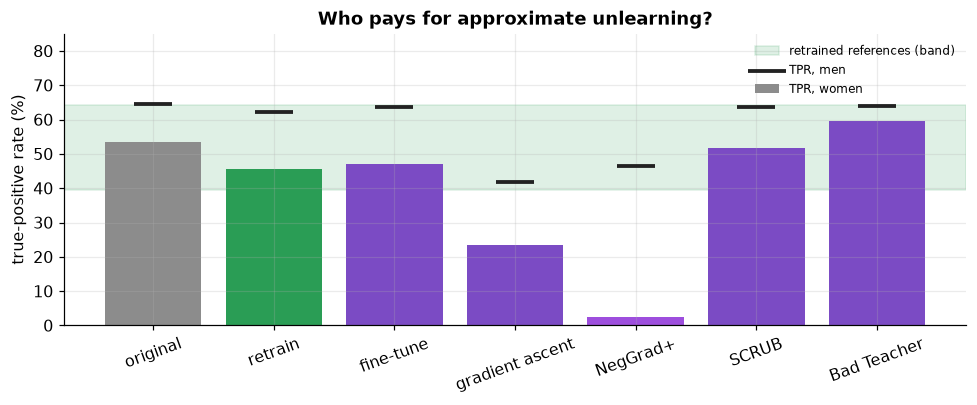

In [9]:
fig, ax = plt.subplots(figsize=(9, 3.8))
order = list(runs)
ax.axhspan(100 * (ref_tpr.mean() - half), 100 * (ref_tpr.mean() + half), color=viz.RETRAIN, alpha=0.15, label="retrained references (band)")
ax.bar(range(len(order)), 100 * table.loc[order, "TPR_women"], color=[viz.color_for(n) for n in order], label="TPR, women")
ax.scatter(range(len(order)), 100 * fair.loc[order, "TPR_men"], marker="_", s=600, color=viz.INK, lw=2.5, label="TPR, men", zorder=3)
ax.set_xticks(range(len(order))); ax.set_xticklabels(order, rotation=20); ax.set_ylabel("true-positive rate (%)")
ax.set_ylim(0, 85); ax.legend(fontsize=8, loc="upper right"); ax.set_title("Who pays for approximate unlearning?")
plt.tight_layout(); plt.show()

**Read that again.** With 30% of the high-earning women deleted, the retrained references keep the women's TPR close
to the original's on average (about 52% vs 54%). Now look at the two methods that push *away* from the forget set :

- **Gradient ascent** damages everyone : both TPRs fall by 20-30 points, and it fails UTILITY too.
- **NegGrad+** does something worse and more specific. The women's TPR falls from 54% to about **2%**, while the men's
  falls by about 18 points. The TPR gap quadruples. It did not remove 233 people. It taught the model that *women who
  look like those 233 people* earn less, a **new, method-made bias** on top of anything the deletions caused. Without
  the FAIRNESS column, the audit would only have said "UTILITY ✗, three points".

Two more things to notice.

- **Fine-tuning on D_r passes the entire gate here.** Tabular data is memorised far less than Carol's digits : the
  original is right on 62% of the 233 deleted rows, retrained models on 49% ± 6. Two epochs of continued training wash
  out that modest influence, the opposite of Problem 8. *How much* the model memorised decides which methods work, and
  that is why the audit has to be re-run on every new kind of data.
- **The fairness band is wide** : seed alone moves the women's TPR of a retrained model between about 42% and 61%. A
  fairness number from *one* model is a sample, exactly like forget accuracy in Problem 6. Measure it against several
  references, or the gate will be either blind or trigger-happy.

#### Fixing it : mitigation after an exact unlearning

Back to the classical model, and the 60% skewed wave served by exact retraining. The model is lawful and exact, and it
is now clearly unfair. A standard mitigation is **post-processing** : choose a separate decision threshold per group so
that the TPRs match (Hardt, Price & Srebro 2016, implemented as fairlearn's `ThresholdOptimizer`, which the book's
fairness chapter uses). It needs no retraining, so it does not interfere with the unlearning.

In [10]:
# Mitigation: equal-opportunity post-processing on the exactly-unlearned model
class Prefit(ClassifierMixin, BaseEstimator):
    """Wrap any model with predict_proba so fairlearn can use it without refitting."""
    def __init__(self, model=None): self.model = model
    def fit(self, X, y): return self
    def __sklearn_is_fitted__(self): return True      # the wrapped model is already trained
    @property
    def classes_(self): return np.array([0, 1])
    def predict_proba(self, X): return self.model.predict_proba(X)
    def predict(self, X): return self.model.predict(X)

forget60 = np.random.default_rng(1).choice(women_hi, int(0.60 * len(women_hi)), replace=False)
keep60 = np.setdiff1d(np.arange(n_train), forget60)
exact60 = classical.LogisticNewton(lam=LAM).fit(X_train[keep60], y_train[keep60])
post = ThresholdOptimizer(estimator=Prefit(exact60), constraints="true_positive_rate_parity", prefit=True,
                          predict_method="predict_proba", objective="accuracy_score")
post.fit(X_train[keep60], y_train[keep60], sensitive_features=m_train.sex.values[keep60])   # retain data only
mit = pd.DataFrame({"original (no deletions)": fairness(original.predict(X_test)),
                    "after 60% wave (exact retrain)": fairness(exact60.predict(X_test)),
                    "+ equal-opportunity thresholds": fairness(post.predict(X_test, sensitive_features=m_test.sex.values, random_state=0))}).T
print(mit.round(3).to_string())

                                accuracy  TPR_women  TPR_men  TPR_gap  selected_women  selected_men
original (no deletions)            0.857      0.506    0.635    0.129           0.076         0.261
after 60% wave (exact retrain)     0.852      0.311    0.635    0.323           0.042         0.263
+ equal-opportunity thresholds     0.855      0.533    0.594    0.061           0.082         0.239


The per-group thresholds bring the women's TPR back up, close to the men's, at no cost in overall accuracy, using
**only the retain data** (the thresholds are fitted without the deleted people, so the mitigation does not quietly
re-use them). It is not free for everyone : the men's TPR drops about four points, because equalising moves both
thresholds. That trade-off is a decision someone has to own.

> 🔴 **For practitioners :** post-processing is the quickest fix, not the only one, and it has costs of its own.
> Group-specific thresholds use the sensitive attribute at decision time, which some jurisdictions and sectors restrict
> (for example, disparate-treatment rules in US credit). Alternatives : reweighting the remaining data, in-processing
> constraints (fairlearn's `ExponentiatedGradient`), or collecting more representative data. Whatever you choose,
> **log it** : the erasure log, the fairness metric over time and the mitigation belong in the same evidence record as
> the unlearning audit (Problem 11), and in the model card.

----
#### OUTCOME :

| | Classical (logistic, Newton removal) | Deep (MLP, approximate methods) |
|---|---|---|
| One request | ✅ matches retrain, gradient-norm certificate | depends on the method (Problem 11) |
| Skewed wave, exact unlearning | ⚠️ women's TPR collapses as the wave grows : the **data** changed | ⚠️ same risk |
| Skewed wave, approximate unlearning | Newton step drifts from the retrain as the batch grows | ❌ GA / NegGrad+ add a **method-made bias**; ✅ fine-tune passes (low memorisation) |
| Detected by accuracy monitoring? | ❌ | ❌ |
| Detected by a per-group fairness check? | ✅ | ✅ |
| Fix | error budget → retrain; post-processing for the data effect | exact methods; FAIRNESS in the gate; post-processing |

#### Key Takeaways :

- Erasure requests are **not random**. When they correlate with a group *and* a label, even perfect unlearning shifts
  the model's behaviour for that group.
- Accuracy dashboards miss it completely. Track **per-group metrics across the deletion log**.
- One Newton step is near-exact for small batches and drifts for large ones. Keep an **error budget**, then retrain.
- Approximate methods that "push away" from the forget set (GA, NegGrad+) can create **new, method-made bias** when the
  forget set is demographically homogeneous.
- Add **FAIRNESS** to the unlearning gate, judged against *several* references because fairness metrics vary with the
  seed. Mitigate with post-processing or reweighting, using retain data only, and record it.
- Low memorisation (tabular data) makes simple methods like fine-tuning viable. Re-audit for every new kind of data.

#### TASK :
1. Repeat the wave experiment with requests skewed by **race** instead of sex (`meta.race`). Which group's TPR moves,
   and by how much? Is the effect larger or smaller for a smaller group?
2. Implement a **multi-step** Newton removal (repeat `unlearn_newton` 3 times). How much of the drift at 90% does it
   remove? Compare with the cost of a retrain.
3. Re-run the deep-model audit with NegGrad+ at `alpha=0.99`. Does the method-made bias go away? Does FORGET pass?
4. Write the **one-paragraph policy** your company would put in its erasure procedure : who monitors the per-group
   metrics, what threshold triggers a mitigation, and who signs it off. (Problem 17 collects these.)

#### ❓ Open question → Problem 13
Here, each person was one row, and their influence on a well-generalising model was small. **What happens when a
person *is* the class, as in face recognition, where a model has learned to recognise *you*, and you withdraw your
consent?** That is Problem 13.